# MS-DSA-NET — этап 2a: дообучение на UHB с доменными аугментациями, чистый тест на IDEAS

**Почему так, а не сразу на IDEAS.** Этап 1 показал две причины провала на IDEAS:
1. **Интенсивности** другого сканера — Nyúl дал +17 п.п. sSens без обучения;
2. **Толстосрезовый FLAIR** — у 17 из 34 пациентов срезы 5 мм, sSens у них 0.18 против 0.67 при 1 мм.

Обе причины можно «показать» модели, не трогая IDEAS: дообучаем на UHB (85 FCD II, точные маски), имитируя толстые срезы FLAIR
и разброс контраста/неоднородности. Тогда **все 34 пациента IDEAS остаются нетронутым тестом** — без кросс-валидации и без грубых резекционных масок.
Если этого не хватит — этап 2b: + IDEAS со слабой разметкой в кросс-валидации.

**Валидация** (выбор чекпоинта) — 10 пациентов UHB, отложенных из обучения, в двух видах: как есть и с FLAIR, «пересобранным» срезами 5 мм.
IDEAS в обучении и выборе модели не участвует.

**Сначала** запустите с `SMOKE = True` (≈5 мин): проверка памяти и скорости. Ноутбук скажет, сколько займёт полное обучение.
Потом `SMOKE = False`, Kernel → Restart → Run All. Обучение продолжается с места остановки (чекпоинт каждую эпоху).

## 1. Конфигурация

In [1]:
import os, sys, time, json, subprocess
from pathlib import Path

os.nice(15)
try:
    import psutil; psutil.Process().ionice(psutil.IOPRIO_CLASS_IDLE)
except Exception as e: print("ionice:", e)
FSLDIR, VENV_BIN = Path.home() / "fsl", Path(sys.executable).parent
os.environ.update(FSLDIR=str(FSLDIR), FSLOUTPUTTYPE="NIFTI_GZ")
_p = [p for p in os.environ["PATH"].split(":") if p and p not in (str(VENV_BIN), f"{FSLDIR}/bin", f"{FSLDIR}/share/fsl/bin")]
os.environ["PATH"] = ":".join([str(VENV_BIN)] + _p + [f"{FSLDIR}/share/fsl/bin", f"{FSLDIR}/bin"])

PROJ    = Path.home() / "projects/mri/ms_dsa_net"
REPO    = PROJ / "MS-DSA-NET"
WEIGHTS = REPO / "pretrained/model.pth"
MNI     = REPO / "inputs/MNI152_T1_1mm.nii.gz"
CKPT    = PROJ / "checkpoints/stage2a"; CKPT.mkdir(parents=True, exist_ok=True)

# ---------- режим ----------
SMOKE = False              # True: 1 короткая эпоха для проверки памяти/скорости; затем False

# ---------- ресурсы ----------
GPU_ID = 1
GPU_TEMP_PAUSE, GPU_TEMP_RESUME = 80, 72     # при обучении нагрузка непрерывная — порог ниже, чем при инференсе
TEMP_CHECK_EVERY = 10                        # итераций
MAX_CPU, NUM_WORKERS = 8, 4                  # процессов подготовки данных
CACHE_RATE = 1.0                             # доля объёмов в RAM (~65 МБ на пациента; 75 пациентов ≈ 5 ГБ)

# ---------- обучение ----------
EPOCHS          = 100
LR, WD          = 1e-4, 1e-5                 # в 5–10 раз ниже обычного: дообучаем, а не учим с нуля
PATCHES_PER_CASE, ACCUM = 4, 1               # 2 окна 128³ за шаг; при нехватке памяти: 1 и ACCUM = 2
AMP             = True
VAL_EVERY, N_VAL, SEED = 2, 10, 0
THICK_PROB, THICK_RANGE = 0.7, (2.0, 6.0)    # имитация толстых срезов FLAIR
PATCH, OVERLAP = (128, 128, 128), 0.25

os.environ["CUDA_VISIBLE_DEVICES"] = str(GPU_ID)
for p in (Path.cwd(), PROJ):
    if (p / "msdsa_lib.py").exists() and str(p) not in sys.path: sys.path.insert(0, str(p))
import msdsa_lib as ml
if SMOKE: EPOCHS, VAL_EVERY, N_VAL_RUN = 1, 1, 3
else: N_VAL_RUN = N_VAL
print("SMOKE" if SMOKE else "Полное обучение", "| GPU", GPU_ID, "| nice", os.nice(0))

Полное обучение | GPU 1 | nice 15


## 2. Окружение, модель, данные UHB

In [2]:
import numpy as np, pandas as pd, nibabel as nib, torch, monai
import matplotlib.pyplot as plt
from monai.inferers import sliding_window_inference
torch.set_num_threads(2)
sys.path.insert(0, str(REPO))
from networks2 import MS_DSA_NET
device = torch.device("cuda")
print("torch", torch.__version__, "| monai", monai.__version__, "|", torch.cuda.get_device_name(0))
free, total = torch.cuda.mem_get_info(); print(f"GPU память свободна: {free/2**30:.1f} / {total/2**30:.1f} ГБ")

def gpu_temp():
    out = subprocess.run(["nvidia-smi", "-i", str(GPU_ID), "--query-gpu=temperature.gpu", "--format=csv,noheader,nounits"],
                         capture_output=True, text=True).stdout.strip()
    return int(out) if out.isdigit() else -1
PAUSE_SEC = [0.0]                      
def wait_cool():
    if gpu_temp() >= GPU_TEMP_PAUSE:
        t0 = time.time()
        while gpu_temp() > GPU_TEMP_RESUME: time.sleep(10)
        PAUSE_SEC[0] += time.time() - t0

def build_model():
    return MS_DSA_NET(spatial_dims=3, in_channels=2, out_channels=2, img_size=list(PATCH), feature_size=16, pos_embed=True,
                      project_size=64, sa_type="parallel", norm_name="instance",
                      act_name=("leakyrelu", {"inplace": True, "negative_slope": 0.01}), res_block=True, bias=False, dropout_rate=0.1)
def load_weights(m, path):
    sd = torch.load(path, map_location="cpu"); sd = sd.get("model", sd.get("state_dict", sd))
    m.load_state_dict({k.replace("module.", "", 1): v for k, v in sd.items()}, strict=True); return m

UHB = ml.Dataset("UHB", "ds004199", PROJ / "data/ds004199", PROJ / "work_uhb", PROJ / "outputs_uhb", gt_space="flair")
uhb_all = sorted(p.name for p in (UHB.work_dir / "fsl").iterdir()
                 if (p / "gt_reg.nii.gz").exists() and (p / "t1_reg_brain_mask.nii.gz").exists())
rng = np.random.default_rng(SEED)
val_subs = sorted(rng.choice(uhb_all, N_VAL, replace=False).tolist())
train_subs = [s for s in uhb_all if s not in val_subs]
print(f"UHB: {len(uhb_all)} | обучение {len(train_subs)} | валидация {len(val_subs)}: {val_subs}")
json.dump(dict(train=train_subs, val=val_subs), open(CKPT / "split.json", "w"), indent=1)

torch 2.0.1+cu117 | monai 1.2.0 | NVIDIA RTX A4000
GPU память свободна: 14.4 / 14.6 ГБ
UHB: 85 | обучение 75 | валидация 10: ['sub-00003', 'sub-00006', 'sub-00014', 'sub-00033', 'sub-00048', 'sub-00055', 'sub-00076', 'sub-00092', 'sub-00120', 'sub-00126']


## 3. Аугментации  
К оригинальным (кроп pos/neg, отражения, сдвиг интенсивности, шум) добавлены: толстые срезы FLAIR, неоднородность поля, гамма, нелинейный сдвиг гистограммы.

Loading dataset: 100%|██████████| 75/75 [00:19<00:00,  3.75it/s]


Кэш: 75 объёмов за 20 с


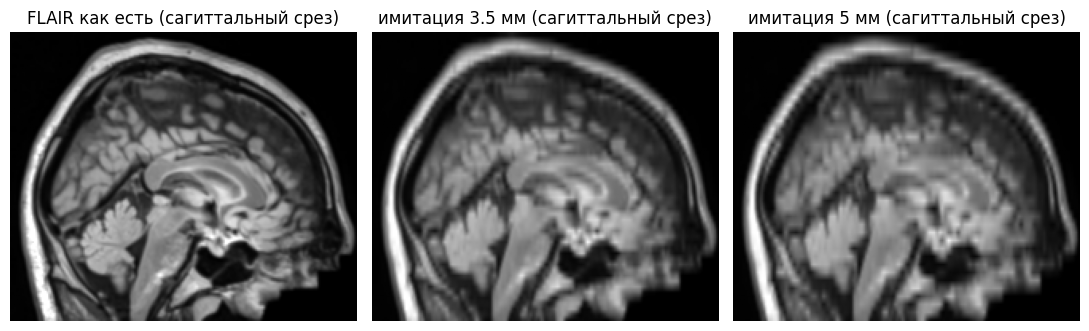

In [3]:
from monai.transforms import (Compose, LoadImaged, EnsureChannelFirstd, Orientationd, ScaleIntensityRangePercentilesd,
    CastToTyped, RandCropByPosNegLabeld, RandFlipd, RandRotated, RandBiasFieldd, RandAdjustContrastd,
    RandHistogramShiftd, RandShiftIntensityd, RandGaussianNoised, EnsureTyped, RandomizableTransform, MapTransform)
from monai.data import CacheDataset, DataLoader

class RandThickSliceFLAIRd(RandomizableTransform, MapTransform):
    """С вероятностью prob FLAIR (канал 1) «пересобирается» срезами толщиной U(t_range) мм; ось — чаще S-I."""
    def __init__(self, keys=("image",), prob=0.7, t_range=(2.0, 6.0), axes=(2, 2, 2, 2, 1)):
        MapTransform.__init__(self, keys); RandomizableTransform.__init__(self, prob)
        self.t_range, self.axes = t_range, axes
    def __call__(self, data):
        d = dict(data); self.randomize(None)
        if not self._do_transform: return d
        t = self.R.uniform(*self.t_range); ax = int(self.R.choice(self.axes))
        img = d["image"]; fl = np.asarray(img[1].detach().cpu() if torch.is_tensor(img) else img[1])
        new = ml.degrade_axis(fl, t, axis=ax, rng=np.random.default_rng(self.R.randint(1 << 30)))
        img[1] = torch.as_tensor(new) if torch.is_tensor(img) else new
        return d

KEYS = ["image", "label"]
det = [LoadImaged(keys=KEYS, image_only=False), EnsureChannelFirstd(keys=KEYS), Orientationd(keys=KEYS, axcodes="RAS"),
       ScaleIntensityRangePercentilesd(keys=["image"], lower=0.5, upper=99.5, b_min=0, b_max=1, clip=True, channel_wise=True),
       CastToTyped(keys=["label"], dtype=np.uint8)]
rand = [RandCropByPosNegLabeld(keys=KEYS, label_key="label", spatial_size=PATCH, pos=1, neg=1,
                               num_samples=PATCHES_PER_CASE, image_key=None, image_threshold=0),
        RandThickSliceFLAIRd(prob=THICK_PROB, t_range=THICK_RANGE),
        RandFlipd(keys=KEYS, spatial_axis=[0], prob=0.5), RandFlipd(keys=KEYS, spatial_axis=[1], prob=0.5),
        RandFlipd(keys=KEYS, spatial_axis=[2], prob=0.5),
        RandRotated(keys=KEYS, range_x=0.26, range_y=0.26, range_z=0.26, mode=("bilinear", "nearest"), prob=0.3),
        RandBiasFieldd(keys=["image"], coeff_range=(0.0, 0.3), prob=0.3),
        RandAdjustContrastd(keys=["image"], gamma=(0.7, 1.5), prob=0.3),
        RandHistogramShiftd(keys=["image"], num_control_points=(5, 10), prob=0.3),
        RandShiftIntensityd(keys=["image"], offsets=0.1, prob=0.5),
        RandGaussianNoised(keys=["image"], std=0.05, prob=0.3),
        EnsureTyped(keys=KEYS, dtype=torch.float32)]
train_tf = Compose(det + rand)

def item(ds, s):
    d = ds.fsl(s); return {"image": [str(d / "t1_reg.nii.gz"), str(d / "flair_reg.nii.gz")], "label": str(d / "gt_reg.nii.gz")}
tr_items = [item(UHB, s) for s in (train_subs[:6] if SMOKE else train_subs)]
t0 = time.time()
train_ds = CacheDataset(tr_items, train_tf, cache_rate=CACHE_RATE, num_workers=NUM_WORKERS)
train_loader = DataLoader(train_ds, batch_size=1, shuffle=True, num_workers=NUM_WORKERS, pin_memory=True,
                          persistent_workers=NUM_WORKERS > 0)
print(f"Кэш: {len(train_ds)} объёмов за {time.time()-t0:.0f} с")

# визуальная проверка аугментации толстых срезов
x, _, _, _ = ml.load_arrays(UHB, train_subs[0])
fig, ax = plt.subplots(1, 3, figsize=(11, 3.6))
for a, (t, ttl) in zip(ax, [(1, "FLAIR как есть"), (3.5, "имитация 3.5 мм"), (5, "имитация 5 мм")]):
    f = ml.degrade_axis(x[1], t, axis=2, offset=0.0) if t > 1 else x[1]
    a.imshow(np.rot90(f[91, :, :]), cmap="gray"); a.set_title(ttl + " (сагиттальный срез)"); a.axis("off")
plt.tight_layout(); plt.show()

## 4. Валидация: UHB-val как есть и с FLAIR 5 мм

In [4]:
POST = ml.Post(brain=True, min_vox=100)       # постобработка, выбранная на этапе 1

def make_run_sw(m):
    def run_sw(x, sw):
        with torch.no_grad(), torch.autocast("cuda", enabled=AMP):
            return sliding_window_inference(x, PATCH, sw, m, overlap=OVERLAP)
    return run_sw

VAL_CACHE = {}
def val_arrays(s, thick):
    k = (s, thick)
    if k not in VAL_CACHE:
        x, gt, brain, _ = ml.load_arrays(UHB, s)
        if thick: x = x.copy(); x[1] = ml.degrade_axis(x[1], thick, axis=2, offset=0.0)
        VAL_CACHE[k] = (x, gt, brain)
    return VAL_CACHE[k]

def validate(m, subs):
    m.eval(); infer = ml.make_infer(make_run_sw(m), device, 2)
    out = {}
    for thick in (None, 5.0):
        rows = []
        for s in subs:
            x, gt, brain = val_arrays(s, thick)
            rows.append(ml._metrics(infer(x), gt, brain, POST))
        d = pd.DataFrame(rows); tag = "thick5" if thick else "clean"
        out.update({f"{tag}_sSens": d.detected.mean(), f"{tag}_top1": d.top_hit.mean(),
                    f"{tag}_nFPC": d.nFPC.mean(), f"{tag}_Dice": d.Dice.mean()})
    out["score"] = (out["thick5_sSens"] + out["thick5_top1"] + out["clean_sSens"] + out["clean_top1"]) / 4 \
                   - 0.05 * (out["thick5_nFPC"] + out["clean_nFPC"])
    m.train(); return out

model = load_weights(build_model(), WEIGHTS).to(device)
t0 = time.time(); v0 = validate(model, val_subs[:N_VAL_RUN])
print(f"Исходные веса ({time.time()-t0:.0f} с):", {k: round(v, 3) for k, v in v0.items()})

Исходные веса (57 с): {'clean_sSens': 0.9, 'clean_top1': 0.8, 'clean_nFPC': 0.1, 'clean_Dice': 0.652, 'thick5_sSens': 0.8, 'thick5_top1': 0.8, 'thick5_nFPC': 0.1, 'thick5_Dice': 0.608, 'score': 0.815}


## 5. Обучение  
Чекпоинт каждую эпоху (`last.pt`), лучший по валидации — `best.pt`. Прерывание (■) безопасно: повторный запуск продолжит.

In [5]:
from monai.losses import DiceCELoss
loss_fn = DiceCELoss(to_onehot_y=True, softmax=True, include_background=False, lambda_dice=1.0, lambda_ce=1.0)
opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WD)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=max(EPOCHS, 1), eta_min=LR / 20)
scaler = torch.cuda.amp.GradScaler(enabled=AMP)
log, start, best = [dict(epoch=0, loss=np.nan, **v0)], 1, v0["score"]

last = CKPT / "last.pt"
if last.exists() and not SMOKE:
    ck = torch.load(last, map_location="cpu")
    model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"]); sched.load_state_dict(ck["sched"])
    scaler.load_state_dict(ck["scaler"]); log, start, best = ck["log"], ck["epoch"] + 1, ck["best"]
    print(f"Продолжаю с эпохи {start}, лучший score {best:.3f}")

torch.cuda.reset_peak_memory_stats()
model.train()
for epoch in range(start, EPOCHS + 1):
    t_ep, losses, n_it = time.time(), [], 0
    PAUSE_SEC[0] = 0.0
    opt.zero_grad(set_to_none=True)
    for it, batch in enumerate(train_loader):
        if SMOKE and it >= 12: break
        if it % TEMP_CHECK_EVERY == 0: wait_cool()
        x = batch["image"].to(device, non_blocking=True); y = batch["label"].to(device, non_blocking=True)
        with torch.autocast("cuda", enabled=AMP):
            loss = loss_fn(model(x), y) / ACCUM
        if not torch.isfinite(loss):                       # защита от переполнения fp16
            print(f"  [итерация {it}: loss не число — пропущена]"); opt.zero_grad(set_to_none=True); continue
        scaler.scale(loss).backward()
        if (it + 1) % ACCUM == 0:
            scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(model.parameters(), 12.0)
            scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True)
        losses.append(loss.item() * ACCUM); n_it += 1
    sched.step()
    sec_it = (time.time() - t_ep) / max(n_it, 1)
    rec = dict(epoch=epoch, loss=float(np.mean(losses)), sec_per_it=sec_it, lr=opt.param_groups[0]["lr"],
               mem_GB=torch.cuda.max_memory_allocated() / 2**30, temp=gpu_temp())
    if epoch % VAL_EVERY == 0 or epoch == EPOCHS:
        rec.update(validate(model, val_subs[:N_VAL_RUN]))
        if rec["score"] > best and not SMOKE:
            best = rec["score"]; torch.save({"model": model.state_dict()}, CKPT / "best.pt"); rec["best"] = True
    log.append(rec)
    if not SMOKE:
        torch.save(dict(model=model.state_dict(), opt=opt.state_dict(), sched=sched.state_dict(),
                        scaler=scaler.state_dict(), epoch=epoch, best=best, log=log), last)
        rec["pause_s"] = PAUSE_SEC[0]
    print(f"эпоха {epoch:3d} | loss {rec['loss']:.3f} | {sec_it:.2f} с/итер | {rec['mem_GB']:.1f} ГБ | {rec['temp']}°C | паузы {PAUSE_SEC[0]:.0f} с"
          + (f" | val: clean sSens {rec['clean_sSens']:.2f} top1 {rec['clean_top1']:.2f} nFPC {rec['clean_nFPC']:.2f}"
             f" ; 5мм sSens {rec['thick5_sSens']:.2f} top1 {rec['thick5_top1']:.2f} nFPC {rec['thick5_nFPC']:.2f}"
             f" | score {rec['score']:.3f}{' ★' if rec.get('best') else ''}" if 'score' in rec else ""), flush=True)

pd.DataFrame(log).to_csv(CKPT / ("smoke_log.csv" if SMOKE else "train_log.csv"), index=False)

Продолжаю с эпохи 5, лучший score 0.820
эпоха   5 | loss 0.606 | 1.01 с/итер | 7.8 ГБ | 78°C | паузы 30 с
эпоха   6 | loss 0.622 | 1.14 с/итер | 7.8 ГБ | 78°C | паузы 41 с | val: clean sSens 0.90 top1 0.50 nFPC 1.80 ; 5мм sSens 0.90 top1 0.60 nFPC 2.00 | score 0.535
эпоха   7 | loss 0.614 | 1.12 с/итер | 7.8 ГБ | 77°C | паузы 41 с
эпоха   8 | loss 0.639 | 1.13 с/итер | 7.8 ГБ | 78°C | паузы 41 с | val: clean sSens 0.90 top1 0.70 nFPC 0.50 ; 5мм sSens 0.90 top1 0.70 nFPC 0.60 | score 0.745
эпоха   9 | loss 0.632 | 1.13 с/итер | 7.8 ГБ | 78°C | паузы 41 с
эпоха  10 | loss 0.619 | 1.13 с/итер | 7.8 ГБ | 80°C | паузы 41 с | val: clean sSens 0.90 top1 0.70 nFPC 0.60 ; 5мм sSens 0.90 top1 0.70 nFPC 0.50 | score 0.745
эпоха  11 | loss 0.604 | 0.99 с/итер | 7.8 ГБ | 80°C | паузы 30 с
эпоха  12 | loss 0.605 | 1.26 с/итер | 7.8 ГБ | 77°C | паузы 51 с | val: clean sSens 0.90 top1 0.80 nFPC 0.40 ; 5мм sSens 0.80 top1 0.60 nFPC 0.30 | score 0.740
эпоха  13 | loss 0.616 | 1.12 с/итер | 7.8 ГБ | 78°C

## 6. Кривые обучения

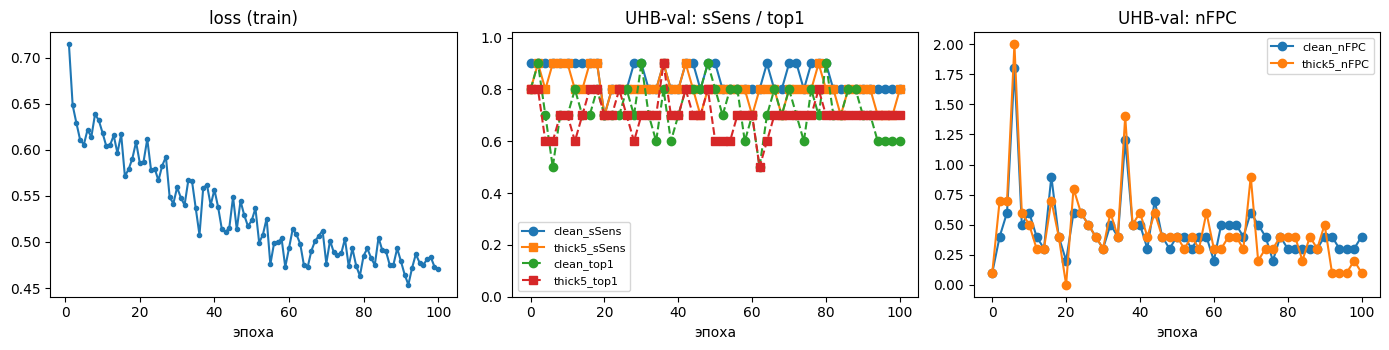

,epoch,loss,clean_sSens,clean_top1,clean_nFPC,clean_Dice,thick5_sSens,thick5_top1,thick5_nFPC,thick5_Dice,score,sec_per_it,lr,mem_GB,temp,best,pause_s
0,0,NaN,0.9,0.8,0.1,0.652,0.8,0.8,0.1,0.608,0.815,NaN,NaN,NaN,NaN,NaN,NaN
2,2,0.648,0.9,0.9,0.4,0.542,0.9,0.8,0.7,0.519,0.820,0.981,0.0,7.766,80.0,True,NaN
4,4,0.611,0.9,0.7,0.6,0.502,0.8,0.6,0.7,0.467,0.685,1.265,0.0,7.766,77.0,NaN,NaN
6,6,0.622,0.9,0.5,1.8,0.422,0.9,0.6,2.0,0.396,0.535,1.136,0.0,7.757,78.0,NaN,40.578
8,8,0.639,0.9,0.7,0.5,0.476,0.9,0.7,0.6,0.461,0.745,1.129,0.0,7.757,78.0,NaN,40.555
10,10,0.619,0.9,0.7,0.6,0.487,0.9,0.7,0.5,0.463,0.745,1.130,0.0,7.757,80.0,NaN,40.547
12,12,0.605,0.9,0.8,0.4,0.546,0.8,0.6,0.3,0.486,0.740,1.263,0.0,7.757,77.0,NaN,50.680
14,14,0.597,0.9,0.7,0.3,0.542,0.8,0.7,0.3,0.499,0.745,1.129,0.0,7.757,78.0,NaN,40.562
16,16,0.572,0.9,0.7,0.9,0.527,0.9,0.8,0.7,0.521,0.745,1.126,0.0,7.757,80.0,NaN,40.538
18,18,0.591,0.9,0.8,0.4,0.496,0.9,0.8,0.4,0.479,0.810,1.128,0.0,7.757,80.0,NaN,40.587


In [6]:
lg = pd.DataFrame(log)
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
ax[0].plot(lg.epoch, lg.loss, "-o", ms=3); ax[0].set_title("loss (train)")
v = lg.dropna(subset=["score"]) if "score" in lg else lg.iloc[:0]
for c, st in (("clean_sSens", "-o"), ("thick5_sSens", "-s"), ("clean_top1", "--o"), ("thick5_top1", "--s")):
    if c in v: ax[1].plot(v.epoch, v[c], st, label=c)
ax[1].set_title("UHB-val: sSens / top1"); ax[1].legend(fontsize=8); ax[1].set_ylim(0, 1.02)
for c in ("clean_nFPC", "thick5_nFPC"):
    if c in v: ax[2].plot(v.epoch, v[c], "-o", label=c)
ax[2].set_title("UHB-val: nFPC"); ax[2].legend(fontsize=8)
for a in ax: a.set_xlabel("эпоха")
plt.tight_layout(); plt.savefig(CKPT / "curves.png", dpi=110); plt.show()
display(v.round(3) if len(v) else lg)

## 7. Тест на IDEAS (34 FCD) — модель ни разу не видела эти данные
Сравниваем с исходной моделью (`pred`) и лучшим вариантом без обучения (`nyul_tta`) из этапа 1 — на тех же пациентах и с той же постобработкой.

In [7]:
assert not SMOKE, "Тест запускается после полного обучения"
meta = pd.read_csv(PROJ / "data/ideas_meta/Metadata_Release_Anon.csv"); meta["sub"] = "sub-" + meta["ID"].astype(str)
meta = meta.drop_duplicates("sub").set_index("sub")
IDEAS = ml.Dataset("IDEAS", "ds005602", PROJ / "data/ds005602", PROJ / "work", PROJ / "outputs", gt_space="t1")
fcd = meta.index[meta.Pathology == "FCD"].tolist()
mask_fn = lambda s: (lambda p: p if p.exists() else None)(PROJ / "data/ideas_masks/masks" / s[4:] / f"{s[4:]}_MaskInRawData.nii.gz")
IDEAS.files = ml.index_with_local_masks(ml.s3_index(IDEAS.s3_id, IDEAS.data_dir / "_s3_index.txt"), fcd, mask_fn)
ideas_subjects = [s for s in fcd if (IDEAS.fsl(s) / "flair_reg.nii.gz").exists()]

model_ft = load_weights(build_model(), CKPT / "best.pt").to(device).eval()
rs = make_run_sw(model_ft)
ref_plain, _ = ml.nyul_reference(UHB, uhb_all)
TEST = {"ft2a": dict(infer=ml.make_infer(rs, device, 4)),
        "ft2a_tta": dict(infer=ml.make_infer(rs, device, 4, tta=True)),
        "ft2a_nyul_tta": dict(infer=ml.make_infer(rs, device, 4, tta=True), harmonizer=ml.Nyul(ref_plain))}
for name, kw in TEST.items():
    ml.run_pipeline(IDEAS, ideas_subjects, variant=name, mni=MNI, n_fsl=4, wait_cool=wait_cool, **kw)

ft2a: 1 download:   0%|          | 0/34 [00:00<?, ?it/s]

ft2a: 2 FSL:   0%|          | 0/34 [00:00<?, ?it/s]

ft2a: 3 GPU:   0%|          | 0/34 [00:00<?, ?it/s]

ft2a: 4 save:   0%|          | 0/34 [00:00<?, ?it/s]

[IDEAS/ft2a] 0.4 мин | готово 34 | ошибок 0


ft2a_tta: 1 download:   0%|          | 0/34 [00:00<?, ?it/s]

... (5 outputs left out)

ft2a_nyul_tta: 2 FSL:   0%|          | 0/34 [00:00<?, ?it/s]

ft2a_nyul_tta: 3 GPU:   0%|          | 0/34 [00:00<?, ?it/s]

ft2a_nyul_tta: 4 save:   0%|          | 0/34 [00:00<?, ?it/s]

[IDEAS/ft2a_nyul_tta] 3.0 мин | готово 34 | ошибок 0


n  sSens   sSens_CI   top1    nFPC  \
variant       post                                                       
исходная      thr=0.5              34  0.382  0.24–0.55  0.206  16.706   
              thr=0.5 +brain ≥100  34  0.324  0.19–0.49  0.206   1.088   
nyul_tta      thr=0.5              34  0.529  0.37–0.69  0.500   1.824   
              thr=0.5 +brain ≥100  34  0.529  0.37–0.69  0.500   0.441   
ft2a          thr=0.5              34  0.500  0.34–0.66  0.412   3.088   
              thr=0.5 +brain ≥100  34  0.471  0.31–0.63  0.412   1.294   
ft2a_tta      thr=0.5              34  0.441  0.29–0.61  0.412   1.500   
              thr=0.5 +brain ≥100  34  0.441  0.29–0.61  0.412   0.735   
ft2a_nyul_tta thr=0.5              34  0.588  0.42–0.74  0.500   2.559   
              thr=0.5 +brain ≥100  34  0.529  0.37–0.69  0.500   1.118   

                                   nFPC_med  noFP_%  PPV_cl   Dice   Prec  \
variant       post                                                          
исходная      thr=0.5                  10.0   0.000   0.031  0.036  0.160   
              thr=0.5 +brain ≥100       1.0  44.118   0.229  0.037  0.256   
nyul_tta      thr=0.5                   1.0  38.235   0.253  0.075  0.340   
              thr=0.5 +brain ≥100       0.0  64.706   0.559  0.075  0.403   
ft2a          thr=0.5                   2.0  14.706   0.153  0.040  0.265   
              thr=0.5 +brain ≥100       1.0  35.294   0.267  0.040  0.297   
ft2a_tta      thr=0.5                   1.0  35.294   0.250  0.037  0.306   
              thr=0.5 +brain ≥100       1.0  47.059   0.375  0.037  0.339   
ft2a_nyul_tta thr=0.5                   1.5  29.412   0.187  0.086  0.360   
              thr=0.5 +brain ≥100       1.0  35.294   0.321  0.086  0.371   

                                   out_brain_%  
variant       post                              
исходная      thr=0.5                   75.085  
              thr=0.5 +brain ≥100        8.333  
nyul_tta      thr=0.5                   10.843  
              thr=0.5 +brain ≥100        2.941  
ft2a          thr=0.5                    5.645  
              thr=0.5 +brain ≥100        0.000  
ft2a_tta      thr=0.5                    0.000  
              thr=0.5 +brain ≥100        0.000  
ft2a_nyul_tta thr=0.5                    1.869  
              thr=0.5 +brain ≥100        3.571

sSens по толщине FLAIR (+brain ≥100):


FLAIR,5 мм,≤3.5 мм
variant,,
ft2a,0.24,0.71
ft2a_nyul_tta,0.29,0.76
ft2a_tta,0.24,0.65
nyul_tta,0.29,0.76
исходная,0.18,0.47


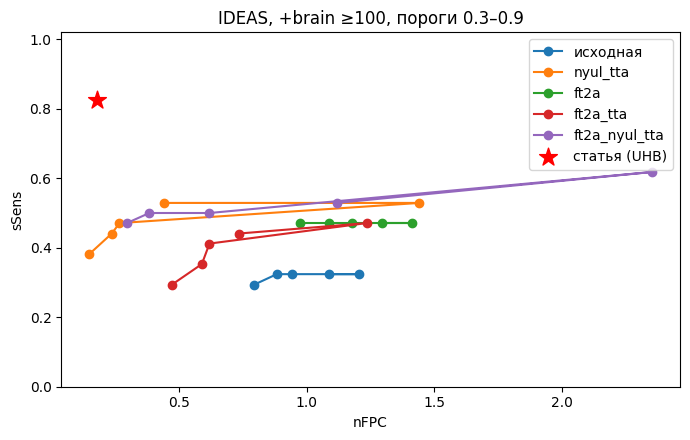

In [8]:
POSTS = [ml.Post(), POST] + [ml.Post(thr=t, brain=True, min_vox=100) for t in (0.3, 0.7, 0.8, 0.9)]
posts = list(dict.fromkeys(POSTS))
ev = []
for v in ["pred", "nyul_tta"] + list(TEST):
    if not any(IDEAS.pred(v).glob("*_prob.nii.gz")): continue
    e = ml.evaluate(IDEAS.pred(v), IDEAS.ref, ideas_subjects, posts); e["variant"] = {"pred": "исходная"}.get(v, v); ev.append(e)
ev = pd.concat(ev)
main = ml.summarize(ev[ev.post.isin([ml.Post().label, POST.label])], by=("variant", "post"))
display(main)

flair_mm = {s: max(nib.load(ml._local(IDEAS, IDEAS.files[s]["flair"])).header.get_zooms()[:3]) for s in ideas_subjects}
e2 = ev[ev.post == POST.label].copy(); e2["FLAIR"] = e2["sub"].map(lambda s: "5 мм" if flair_mm[s] >= 4.5 else "≤3.5 мм")
print("sSens по толщине FLAIR (+brain ≥100):")
display(e2.pivot_table(index="variant", columns="FLAIR", values="detected", aggfunc="mean").round(2))

sw = ml.summarize(ev[ev.post.str.contains(r"\+brain ≥100$")], by=("variant", "post")).reset_index()
fig, ax = plt.subplots(figsize=(7, 4.5))
for v, d in sw.groupby("variant", sort=False): ax.plot(d.nFPC, d.sSens, "o-", label=v)
ax.scatter([ml.PAPER["nFPC"]], [ml.PAPER["sSens"]], marker="*", s=180, c="red", label="статья (UHB)")
ax.set_xlabel("nFPC"); ax.set_ylabel("sSens"); ax.set_ylim(0, 1.02); ax.legend(); ax.set_title("IDEAS, +brain ≥100, пороги 0.3–0.9")
plt.tight_layout(); plt.savefig(IDEAS.out_dir / "stage2a_froc.png", dpi=110); plt.show()
main.to_csv(IDEAS.out_dir / "stage2a_comparison.csv"); ev.to_csv(IDEAS.out_dir / "stage2a_per_subject.csv", index=False)